<div style="display:flex;align-items:center;gap:30px;margin:18px 0"><img src="images/mcdc.png" alt="Metropolitan Chicago Data Science Corps logo" style="width:150px"><img src="images/MortonArboretumLogo.png" alt="The Morton Arboretum logo" style="width:200px"></div>

## MCDC Connection

The Morton Arboretum is an MCDC community partner, and MCDC's [Morton Arboretum data-cleaning project](https://sites.northwestern.edu/mcdc/data-cleaning-morton-arboretum-tree-species/) motivates working carefully with biological measurements. This lesson uses a **separate, publicly archived Morton-affiliated research dataset**, not the street-tree inventory from that project: root-trait measurements from Oh and colleagues' study of 11 tree species at Morton, archived on [Dryad](https://doi.org/10.5061/dryad.vmcvdnd78).

How can we describe a tree using several root measurements at once? Plotting every possible pair quickly becomes difficult. **Principal component analysis (PCA)** creates new numerical coordinates that summarize variation across several features, and the result depends on what we measure and how we scale those measurements. Along the way, the lesson develops transferable skills in data curation, visualization, and critical interpretation. It is an introductory exploration, not a reproduction of the paper's analyses or an assessment of which trees communities should plant.



## Learning objectives

By the end of this lesson, you should be able to:

1. Obtain an archived research dataset and record its provenance.
2. Select numerical features while keeping identifiers and group labels separate.
3. Audit missingness and document the rows retained for analysis.
4. Explain why different numerical scales influence PCA.
5. Standardize features and compare scaled and unscaled PCA.
6. Interpret explained variance, component weights, and observation scores.
7. Evaluate the information lost in a two-dimensional representation.
8. Communicate exploratory findings with appropriate limitations.

**Prerequisites:** Basic Python, pandas selection and filtering, descriptive statistics, and scatter plots. No previous linear algebra is required.

**Suggested duration:** Two 75-minute sessions. Parts 1–5 introduce preparation and scaling; Parts 6–10 develop interpretation and reporting. Exercises can be completed as homework.

## Setup

Run cells in order. Paths are relative to the folder containing this notebook, so it works on any computer. If the workbook is not already in `data/raw/morton_root_traits/`, Part 1 downloads it automatically from a public copy of the original Dryad file. Derived files go in a separate processed folder. Once the workbook is present, the analysis runs without network access.

In [1]:
# Uncomment only if these packages are missing from your notebook environment.
# %pip install pandas numpy openpyxl matplotlib scikit-learn requests

In [2]:
from pathlib import Path
import hashlib
import json
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display

raw_dir = Path("data/raw/morton_root_traits")
processed_dir = Path("data/processed/morton_root_traits_pca")
raw_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
data_path = raw_dir / "final_exudate_data_submission.xlsx"

plt.rcParams.update({"figure.dpi": 120, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Obtain and document the source

The **dataset DOI** identifies the archive record; the **file URL** retrieves the workbook. Keep both so someone can find the documentation even if the download link changes.

1. Open [the Dryad dataset record](https://doi.org/10.5061/dryad.vmcvdnd78).
2. In **Data files**, choose `final_exudate_data_submission.xlsx` from the May 6, 2026 release. The archive API identifies this as version 3.
3. Save it under `data/raw/morton_root_traits/` without editing the workbook.
4. Read the archive's README and methods. Its license is **CC0 1.0**. Cite the researchers even though the data are dedicated to the public domain.

The next cell downloads the workbook only if it is absent. Dryad blocks automated downloads, so the code fetches an unchanged copy from the [public lesson repository](https://github.com/Lizhen0909/mcdc_2026su) and then tries Dryad. Either way, the file is accepted only if its checksum matches Dryad's. If both downloads fail, follow the manual steps above and rerun the cell. Never substitute an HTML error page for a workbook.

**Source citation:** Oh, Young Eui; Midgley, Meghan; McCormack, Luke et al. (2026). *Data from: Plant functional groups and root traits are linked to exudation rates of mature temperate trees*. Dryad. https://doi.org/10.5061/dryad.vmcvdnd78

**Related article:** https://doi.org/10.1111/1365-2435.70363

The SHA-256 checksum below comes from [Dryad's file metadata](https://datadryad.org/api/v2/files/4747058). It verifies the file version, not the scientific accuracy of the observations.

**Acquisition for this lesson:** The workbook was downloaded manually from this record and placed in the raw-data folder on September 5, 2026 after automated downloads returned access errors. Its 23,521 bytes match the SHA-256 value in Dryad's metadata. The unchanged workbook is mirrored in the public lesson repository, so learners do not need a successful Dryad download to run it. The original README remains available through the source page.

In [3]:
DATASET_DOI = "https://doi.org/10.5061/dryad.vmcvdnd78"
DOWNLOAD_URL = "https://datadryad.org/downloads/file_stream/4747058"
MIRROR_URL = ("https://raw.githubusercontent.com/Lizhen0909/mcdc_2026su/main/"
              "data/raw/morton_root_traits/final_exudate_data_submission.xlsx")
EXPECTED_SHA256 = "f7ba355a9480893e9d25f83cf7ef209e4cfba1547419dcef1931187a4b313df4"

if not data_path.exists():
    for url in [MIRROR_URL, DOWNLOAD_URL]:
        try:
            response = requests.get(url, timeout=60)
            response.raise_for_status()
        except requests.RequestException as error:
            print(f"Could not download from {url}: {error}")
            continue
        payload = response.content
        # XLSX is a ZIP-based format. A checksum is the stronger version check.
        if payload.startswith(b"PK") and hashlib.sha256(payload).hexdigest() == EXPECTED_SHA256:
            data_path.write_bytes(payload)
            print(f"Downloaded workbook from {url}")
            break
        print(f"{url} did not return the documented workbook.")
    else:
        raise RuntimeError("Download failed. Use the manual download instructions above.")

actual_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert actual_sha256 == EXPECTED_SHA256, "Workbook differs from the documented release."
print(f"Verified {data_path.name}: {data_path.stat().st_size:,} bytes")

Verified final_exudate_data_submission.xlsx: 23,521 bytes


### Check your understanding

Why record both the DOI and a file checksum? Would matching the checksum prove that every measurement is correct?

## Part 2 — Inspect the workbook before choosing features

A workbook can contain multiple worksheets or explanatory rows. Inspect the sheet names, column names, and preview before deciding which sheet contains observations. The cell below finds the unique sheet containing our required columns; it stops if that choice is ambiguous.

In [4]:
features = ["diameter", "srl", "rtd", "sra", "%N", "branching_intensity"]
metadata_columns = ["tree_ID", "species", "myco", "phylo"]
workbook = pd.ExcelFile(data_path, engine="openpyxl")
print("Sheets:", workbook.sheet_names)

sheets = {name: pd.read_excel(workbook, sheet_name=name) for name in workbook.sheet_names}
for name, sheet in sheets.items():
    print(name, sheet.shape, sheet.columns.tolist())

required = set(features + metadata_columns)
candidates = [name for name, sheet in sheets.items() if required.issubset(sheet.columns)]
if len(candidates) != 1:
    raise ValueError("Inspect workbook headers and select the observation sheet explicitly.")
sheet_name = candidates[0]
df = sheets[sheet_name].copy()
df.index.name = "source_row_index"
print("Selected sheet:", sheet_name)
display(df.head())

Sheets: ['final_exudate_data_stat']
final_exudate_data_stat (60, 23) ['tree_ID', 'species', 'species_scientific', 'myco', 'phylo', 'leaf', 'Combined', 'Combi_leaf_phylo', 'Family', 'er_mass', 'diameter', 'srl', 'rtd', 'sra', '%N', '%C', 'C:N', 'branching_intensity', 'total_exudate_μg_day', 'N_uptake', 'NH4_uptake', 'NO3_uptake', 'mass_g']
Selected sheet: final_exudate_data_stat


,tree_ID,species,species_scientific,myco,phylo,leaf,Combined,Combi_leaf_phylo,Family,er_mass,...,sra,%N,%C,C:N,branching_intensity,total_exudate_μg_day,N_uptake,NH4_uptake,NO3_uptake,mass_g
source_row_index,,,,,,,,,,,,,,,,,,,,,
0,b. cypress_1,T.distichum,Taxodium distichum,AM,Gymnosperm,Deciduous,AM.Gymnosperm,dec_gymno,Cupressaceae,749.140624,...,301.789784,2.003366,48.201004,24.060006,1.797463,38.131258,1101.70200,658.222576,443.479626,0.0509
1,b. cypress_2,T.distichum,Taxodium distichum,AM,Gymnosperm,Deciduous,AM.Gymnosperm,dec_gymno,Cupressaceae,546.803153,...,254.632076,1.554716,47.825893,30.761818,1.750861,11.592227,-681.05200,-337.670959,-343.381181,0.0212
2,b. cypress_3,T.distichum,Taxodium distichum,AM,Gymnosperm,Deciduous,AM.Gymnosperm,dec_gymno,Cupressaceae,367.718883,...,238.855895,1.831549,46.995659,25.658973,2.639587,33.683050,540.89800,298.889792,242.007967,0.0916
3,b. cypress_4,T.distichum,Taxodium distichum,AM,Gymnosperm,Deciduous,AM.Gymnosperm,dec_gymno,Cupressaceae,643.996712,...,260.977337,2.169584,44.773678,20.636988,1.909334,22.733084,577.47000,448.700203,128.770175,0.0353
4,hemlock_1,T.canadensis,Tsuga canadensis,EcM,Gymnosperm,Evergreen,EcM.Gymnosperm,ev_gymno,Pinaceae,1776.793149,...,146.810370,1.503732,48.279308,32.106334,5.031565,599.667688,453.40054,291.964764,161.435776,0.3375


### Choosing the measurement space

We use six traits. Each retained row will be an observation, and each selected column will be a feature. Group labels will color plots **after** PCA is fitted. They do not influence the components.

| Field | Meaning | Unit listed in the archive dictionary |
|---|---|---|
| `diameter` | Mean root diameter | mm |
| `srl` | Root length per unit mass | cm/g |
| `rtd` | Root tissue density | g/cm³ |
| `sra` | Root area per unit mass | cm²/g |
| `%N` | Root nitrogen concentration | % |
| `branching_intensity` | Root tips per unit length | tips/cm |

**Documentation issue:** The archive's methods text lists diameter in cm and SRL in m/g, differing from its dictionary. We retain original numerical values, describe them as archived values, and do not silently choose a conversion. Standardizing a feature removes the effect of a consistent positive unit multiplier. This does not resolve inconsistent units within a column or justify interpreting uncertain absolute values.

`tree_ID` is an identifier, even if stored numerically. `myco` describes fungal association (AM or EcM), and `phylo` describes a plant group. These are not continuous measurements. We also exclude `er_mass` (exudation) to summarize traits independently of that outcome. Adding every numeric column can double-count derived measurements or encode identifiers as distances.

In [5]:
display(df[features].describe().T)
display(df[metadata_columns].head())
print("Rows:", len(df))
print("Distinct species:", df["species"].nunique())
print("Missing tree IDs:", df["tree_ID"].isna().sum())
print("Repeated nonmissing tree IDs:", df.loc[df["tree_ID"].notna(), "tree_ID"].duplicated().sum())
display(df.groupby(["myco", "phylo"], dropna=False).size().rename("observations").to_frame())

,count,mean,std,min,25%,50%,75%,max
diameter,60.0,0.474140,0.120579,0.300900,0.377350,0.432600,0.577075,0.752300
srl,60.0,1246.391862,478.144951,372.509696,907.787250,1212.199829,1570.510612,2408.898438
rtd,60.0,0.561299,0.205013,0.243448,0.419814,0.528565,0.667662,1.012195
sra,60.0,173.274226,50.961612,75.277351,132.934410,171.240264,211.465175,301.789784
%N,60.0,1.630165,0.487034,0.432006,1.338029,1.512966,1.904176,3.247333
branching_intensity,60.0,3.422724,1.504245,0.650314,2.226973,3.436103,4.412641,6.521832


,tree_ID,species,myco,phylo
source_row_index,,,,
0,b. cypress_1,T.distichum,AM,Gymnosperm
1,b. cypress_2,T.distichum,AM,Gymnosperm
2,b. cypress_3,T.distichum,AM,Gymnosperm
3,b. cypress_4,T.distichum,AM,Gymnosperm
4,hemlock_1,T.canadensis,EcM,Gymnosperm


Rows: 60
Distinct species: 11
Missing tree IDs: 0
Repeated nonmissing tree IDs: 0


observations
myco phylo                   
AM   Angiosperm            14
     Gymnosperm            17
EcM  Angiosperm            11
     Gymnosperm            18

## Part 3 — Make a transparent analysis subset

PCA requires finite numerical input. First check whether converting columns to numbers introduces missing values. Then report genuine missingness. Do not treat a missing measurement as zero.

For this introductory analysis we retain complete observations across the six traits. This is a teaching choice, not a claim that missingness is random. The group table below shows whether exclusion changes representation. We retain source row indexes so every score can be traced to its original row. Repeated tree IDs require investigation, not automatic deletion: they may describe repeated samples.

In [6]:
numeric = df[features].apply(pd.to_numeric, errors="coerce")
new_missing = numeric.isna() & df[features].notna()
if new_missing.any().any():
    display(df.loc[new_missing.any(axis=1), features])
    raise ValueError("Nonnumeric trait values need an explicit cleaning decision.")

audit = pd.DataFrame({"missing": numeric.isna().sum(),
                      "infinite": np.isinf(numeric).sum(),
                      "nonpositive": (numeric <= 0).sum()})
display(audit)
keep = np.isfinite(numeric.to_numpy(dtype=float)).all(axis=1)
X = numeric.loc[keep].copy()
meta = df.loc[keep, metadata_columns].copy()
print(f"Retained {len(X)} of {len(df)} observations; excluded {len(df) - len(X)}.")
assert len(X) > len(features), "Too few complete observations for this example."
assert (X.std(ddof=0) > 0).all(), "A selected feature has no variation."
assert X.index.equals(meta.index)

coverage = df.assign(retained=keep).groupby("myco", dropna=False)["retained"].agg(["size", "sum"])
coverage.columns = ["original_rows", "retained_rows"]
coverage["retained_fraction"] = coverage.retained_rows / coverage.original_rows
display(coverage)

,missing,infinite,nonpositive
diameter,0,0,0
srl,0,0,0
rtd,0,0,0
sra,0,0,0
%N,0,0,0
branching_intensity,0,0,0


Retained 60 of 60 observations; excluded 0.


,original_rows,retained_rows,retained_fraction
myco,,,
AM,31,31,1.0
EcM,29,29,1.0


### What the supplied release contains

The May 6 release contains **60 observations and 23 columns**, representing 11 species. All 60 rows have finite values for our six selected traits, and the 60 tree IDs are unique. Thus no observations are removed here. The retained fungal-association counts are 31 AM and 29 EcM. The audit is still useful: a future dataset version or a different choice of features might have missing values.


### Why not fill missing values immediately?

Median imputation would keep more rows, but it would also introduce repeated central values that can alter covariance. Complete-case analysis can distort representation too. Neither choice is automatically neutral. We compare an alternative in the exercises.

## Part 4 — See the scale problem

PCA finds directions with large variance. The implementation centers each feature, but does **not** automatically divide by its standard deviation. A feature with large numerical variance can dominate the result simply because of its measurement scale.

The following plot compares numerical standard deviations in the archived units. These values are not directly comparable biological magnitudes. We use a logarithmic axis only to make their numerical scales visible.

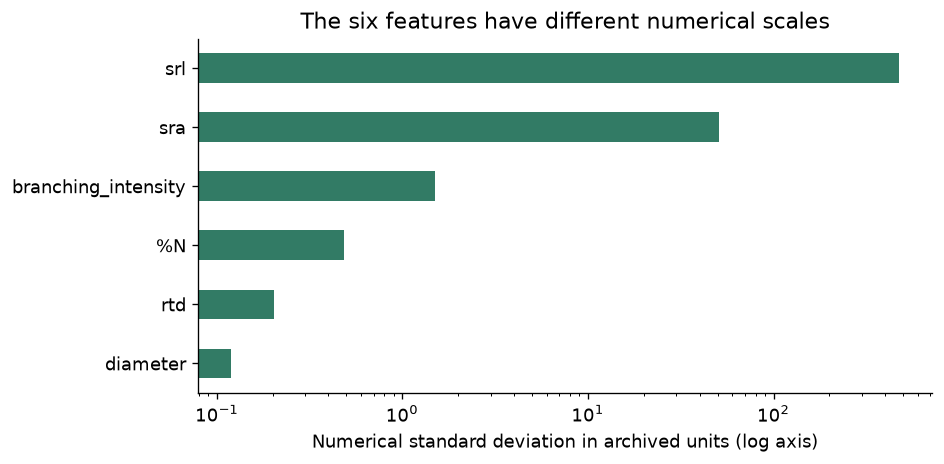

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
X.std(ddof=0).sort_values().plot.barh(ax=ax, color="#327b65")
ax.set_xscale("log")
ax.set_xlabel("Numerical standard deviation in archived units (log axis)")
ax.set_title("The six features have different numerical scales")
fig.tight_layout()
plt.show()

### A first PCA, without scaling

Imagine rotating the axes of a cloud of points. The first principal component (PC1) points along the greatest remaining variation. PC2 is perpendicular to PC1 and captures as much of the remaining variation as possible. With six features there are up to six components.

The new coordinates of observations are **scores**. The weights defining the new axes are **component coefficients**. Explained variance describes variation in the input representation, not prediction accuracy or ecological importance.

In [8]:
pca_raw = PCA(svd_solver="full")
raw_scores = pca_raw.fit_transform(X)
raw_pc1 = pd.Series(pca_raw.components_[0], index=features, name="unscaled_PC1_coefficient")
display(raw_pc1.to_frame())
print(f"Unscaled PC1 explains {pca_raw.explained_variance_ratio_[0]:.1%} of unscaled variance.")

,unscaled_PC1_coefficient
diameter,-0.000174
srl,0.996658
rtd,-0.000075
sra,0.081686
%N,0.000193
branching_intensity,-0.000087


Unscaled PC1 explains 99.5% of unscaled variance.


## Part 5 — Standardize features and repeat PCA

For each feature, standardization subtracts its mean and divides by its standard deviation:

$$z_{ij} = (x_{ij} - \mu_j)/\sigma_j$$

A standardized value of 1 means one standard deviation above that feature's mean. This gives each feature unit variance before PCA. It does not make distributions normal, remove outliers, or establish equal scientific importance.

`StandardScaler` uses population standard deviation (`ddof=0`), while pandas defaults to sample standard deviation (`ddof=1`). We specify the former when checking its output.

This is an exploratory analysis of the entire available subset. If extending it into a predictive model, split the data first and fit both scaling and PCA only on the training data, preferably inside a pipeline. With repeated individuals or species, consider a group-aware split.

In [9]:
scaler = StandardScaler()
Z_array = scaler.fit_transform(X)
Z = pd.DataFrame(Z_array, index=X.index, columns=features)
display(pd.DataFrame({"mean": Z.mean(), "std_ddof0": Z.std(ddof=0)}).round(8))
np.testing.assert_allclose(Z.mean(), 0, atol=1e-10)
np.testing.assert_allclose(Z.std(ddof=0), 1, atol=1e-10)

pca = PCA(svd_solver="full")
scores = pca.fit_transform(Z)
pc_names = [f"PC{i+1}" for i in range(len(features))]
coefficients = pd.DataFrame(pca.components_.T, index=features, columns=pc_names)
display(coefficients.round(3))

,mean,std_ddof0
diameter,-0.0,1.0
srl,-0.0,1.0
rtd,-0.0,1.0
sra,0.0,1.0
%N,-0.0,1.0
branching_intensity,-0.0,1.0


,PC1,PC2,PC3,PC4,PC5,PC6
diameter,-0.182,0.639,0.311,-0.044,0.610,0.296
srl,-0.226,-0.638,0.010,-0.100,0.258,0.682
rtd,0.525,-0.142,-0.478,0.178,0.644,-0.169
sra,-0.490,-0.340,0.262,-0.116,0.381,-0.645
%N,-0.469,0.066,-0.276,0.835,-0.028,0.043
branching_intensity,0.424,-0.211,0.728,0.496,0.011,0.001


### Compare the two representations

The raw and standardized models answer different questions because their notions of variance differ. A lower PC1 percentage after scaling is not a worse result. The denominator has changed.

Squaring coefficients removes arbitrary signs and shows how strongly each feature enters PC1 in its respective representation. These are axis weights, not causal effects or the fraction of each trait explained by PC1.

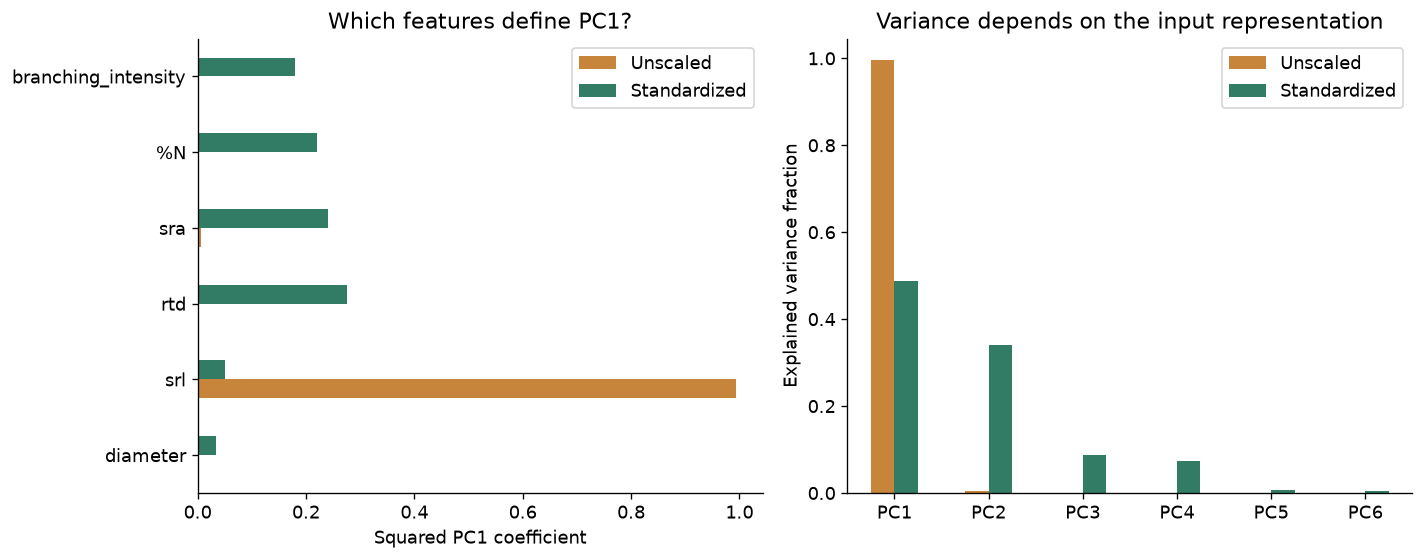

In [10]:
comparison = pd.DataFrame({
    "Unscaled": pca_raw.components_[0] ** 2,
    "Standardized": pca.components_[0] ** 2,
}, index=features)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
comparison.plot.barh(ax=axes[0], color=["#c7853b", "#327b65"])
axes[0].set_xlabel("Squared PC1 coefficient")
axes[0].set_title("Which features define PC1?")
pd.DataFrame({"Unscaled": pca_raw.explained_variance_ratio_,
              "Standardized": pca.explained_variance_ratio_}, index=pc_names).plot.bar(
    ax=axes[1], color=["#c7853b", "#327b65"])
axes[1].set_ylabel("Explained variance fraction")
axes[1].set_title("Variance depends on the input representation")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

### Reading this comparison

In this release, unscaled PC1 explains approximately **99.54%** of numerical variance and is dominated by `srl`. This does not mean one biological trait explains almost all root biology. After standardization, PC1 explains **48.80%** and PC2 **34.00%**. Variation is distributed across more than one direction once feature scales are comparable.


### Experiment: change a unit, not a tree

Multiplying an entire measurement column by 1,000 leaves the biological observations unchanged. Predict what it will do to unscaled PCA and standardized PCA before running this cell. This is an illustrative unit multiplier, not a correction to the archive's uncertain units.

In [11]:
X_changed = X.copy()
X_changed["diameter"] *= 1000
changed_raw = PCA(svd_solver="full").fit(X_changed)
Z_changed = StandardScaler().fit_transform(X_changed)
changed_scaled = PCA(svd_solver="full").fit(Z_changed)

display(pd.DataFrame({
    "original_unscaled_PC1_weight_squared": pca_raw.components_[0] ** 2,
    "changed_unscaled_PC1_weight_squared": changed_raw.components_[0] ** 2,
}, index=features))
np.testing.assert_allclose(Z_array, Z_changed, atol=1e-10)
np.testing.assert_allclose(pca.explained_variance_ratio_,
                           changed_scaled.explained_variance_ratio_, atol=1e-10)
print("Standardized inputs and explained-variance fractions agree after the unit change.")

,original_unscaled_PC1_weight_squared,changed_unscaled_PC1_weight_squared
diameter,3.023517e-08,3.126151e-02
srl,9.933273e-01,9.625659e-01
rtd,5.550310e-09,3.757472e-09
sra,6.672618e-03,6.172568e-03
%N,3.742973e-08,2.978403e-08
branching_intensity,7.557721e-09,8.837803e-10


Standardized inputs and explained-variance fractions agree after the unit change.


## Part 6 — How many components do we need?

A two-dimensional plot is convenient, but it may omit meaningful variation. A **scree plot** shows each component's explained variance, while a cumulative curve shows how much is retained together. Here we calculate the number needed to retain 80% as an illustrative reporting rule. There is no universal threshold that proves a model is adequate.

,explained_fraction,cumulative_fraction
PC1,0.4880,0.4880
PC2,0.3400,0.8280
PC3,0.0863,0.9144
PC4,0.0737,0.9881
PC5,0.0072,0.9953
PC6,0.0047,1.0000


PC1 + PC2 retain 82.8% of standardized variance.
Components required for at least 80%: 2


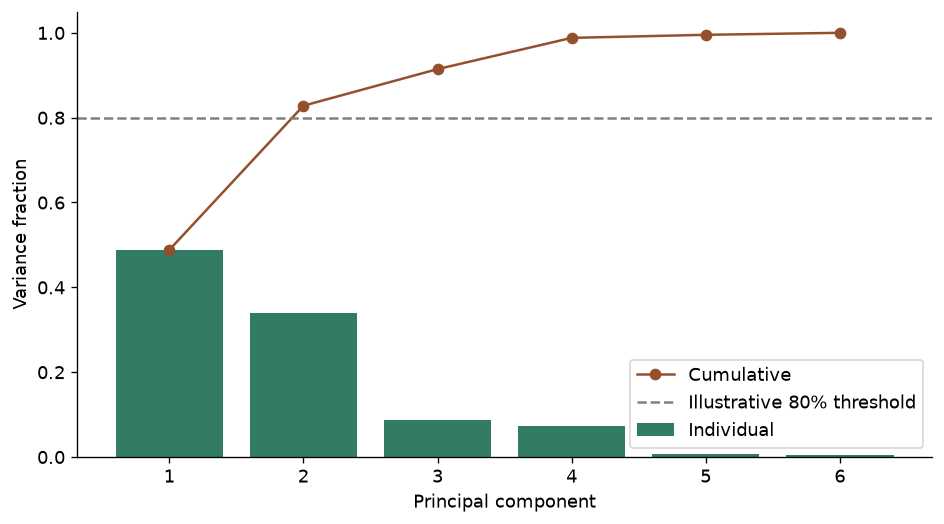

In [12]:
variance_table = pd.DataFrame({
    "explained_fraction": pca.explained_variance_ratio_,
    "cumulative_fraction": np.cumsum(pca.explained_variance_ratio_),
}, index=pc_names)
k80 = int(np.searchsorted(variance_table.cumulative_fraction.to_numpy(), 0.80) + 1)
display(variance_table.round(4))
print(f"PC1 + PC2 retain {variance_table.cumulative_fraction.iloc[1]:.1%} of standardized variance.")
print(f"Components required for at least 80%: {k80}")

fig, ax = plt.subplots(figsize=(8, 4.5))
positions = np.arange(1, len(features) + 1)
ax.bar(positions, variance_table.explained_fraction, color="#327b65", label="Individual")
ax.plot(positions, variance_table.cumulative_fraction, "o-", color="#94502c", label="Cumulative")
ax.axhline(0.80, color="gray", linestyle="--", label="Illustrative 80% threshold")
ax.set(xticks=positions, xlabel="Principal component", ylabel="Variance fraction", ylim=(0, 1.05))
ax.legend()
fig.tight_layout()
plt.show()

## Part 7 — Interpret the component directions

For standardized inputs, a component score is a weighted sum of centered standardized features:

$$\mathrm{PC1}_i = w_1(z_{i1}-\bar z_1) + \cdots + w_6(z_{i6}-\bar z_6).$$

The next cell reconstructs the first observation's score. A large absolute coefficient means that feature contributes strongly to this axis. Features with coefficients of the same sign move together along that axis; opposite signs describe a contrast along it. Other components can carry different relationships.

**Sign is arbitrary:** Reversing an axis and all its scores leaves the geometry unchanged. Avoid assigning a biological meaning to “positive” without first reading the coefficients. Here we call `components_.T` **coefficients**. Some texts use “loadings” for these weights; others reserve that word for coefficients multiplied by the square root of an eigenvalue. Always state the convention.

,contribution_to_first_PC1_score
diameter,0.059372
srl,-0.458459
rtd,-0.662735
sra,-1.247325
%N,-0.362179
branching_intensity,-0.461863


Reconstructed PC1 score: -3.1332


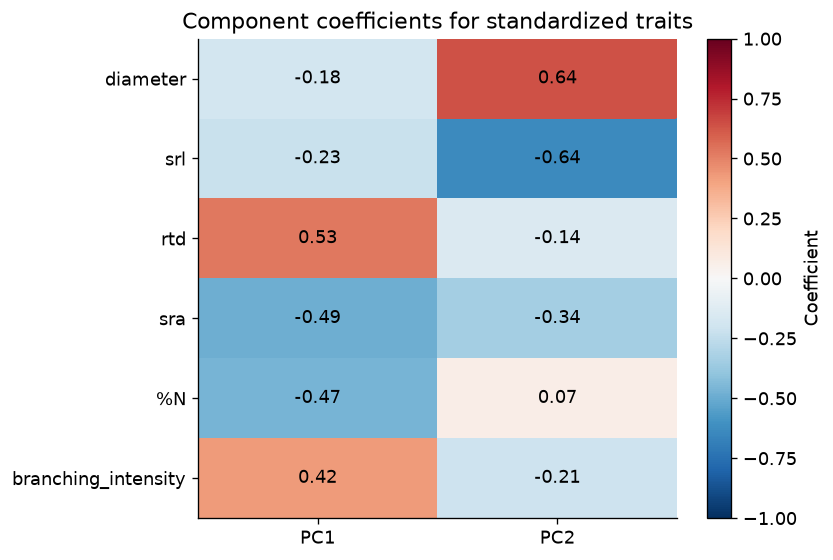

In [13]:
contributions = (Z.iloc[0] - pca.mean_) * coefficients["PC1"]
display(contributions.rename("contribution_to_first_PC1_score").to_frame())
np.testing.assert_allclose(contributions.sum(), scores[0, 0], atol=1e-10)
print("Reconstructed PC1 score:", round(contributions.sum(), 4))

fig, ax = plt.subplots(figsize=(7, 4.8))
matrix = coefficients.iloc[:, :2].to_numpy()
im = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set(xticks=[0, 1], xticklabels=["PC1", "PC2"],
       yticks=np.arange(len(features)), yticklabels=features,
       title="Component coefficients for standardized traits")
for i in range(len(features)):
    for j in range(2):
        ax.text(j, i, f"{matrix[i,j]:.2f}", ha="center", va="center",
                color="white" if abs(matrix[i,j]) > .65 else "black")
fig.colorbar(im, ax=ax, label="Coefficient")
fig.tight_layout()
plt.show()

### Correlations help connect axes back to measurements

A component coefficient is not itself the correlation between a trait and a component score. Calculate these correlations directly when you want to discuss which traits are associated with an axis. Orthogonal components also do not imply independent biological mechanisms.

In [14]:
score_df = pd.DataFrame(scores, index=X.index, columns=pc_names)
trait_score_correlations = pd.DataFrame({
    pc: X.apply(lambda column: column.corr(score_df[pc])) for pc in ["PC1", "PC2"]
})
display(trait_score_correlations.round(3))

,PC1,PC2
diameter,-0.311,0.913
srl,-0.387,-0.911
rtd,0.899,-0.203
sra,-0.839,-0.486
%N,-0.802,0.094
branching_intensity,0.725,-0.301


### A worked interpretation

With the signs shown here, PC1 contrasts higher tissue density and branching intensity with higher specific root area and nitrogen concentration. PC2 mainly contrasts diameter with specific root length. These descriptions follow the fitted coefficients, not a preassigned biological label. An implementation that flips the axis signs should lead to the same interpretation of the contrast.


## Part 8 — Plot observations and add biological context

Each point below represents a retained observation. Nearby points have similar scores on the displayed axes, but can still differ on omitted components. We color points by fungal-association group only after calculating the PCA. This is an unsupervised method, not a classifier trained to separate AM and EcM.

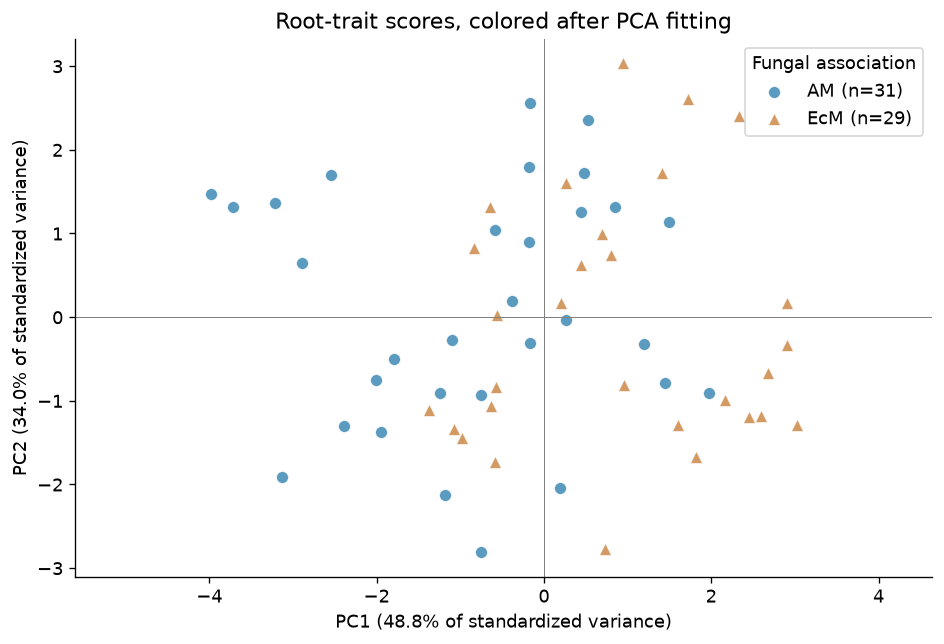

In [15]:
plot_data = score_df.join(meta)
palette = {"AM": "#267aab", "EcM": "#c5782f"}
markers = ["o", "^", "s", "D"]
fig, ax = plt.subplots(figsize=(8, 5.5))
groups = plot_data["myco"].fillna("Missing label").astype(str)
for i, group in enumerate(sorted(groups.unique())):
    subset = plot_data.loc[groups == group]
    ax.scatter(subset.PC1, subset.PC2, label=f"{group} (n={len(subset)})",
               color=palette.get(group, "gray"), marker=markers[i % len(markers)],
               alpha=.75, s=50, edgecolor="white", linewidth=.4)
ax.axhline(0, color="gray", linewidth=.6)
ax.axvline(0, color="gray", linewidth=.6)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of standardized variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of standardized variance)")
ax.set_title("Root-trait scores, colored after PCA fitting")
ax.legend(title="Fungal association")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
plt.show()

### What this plot shows

The first two components retain **82.80%** of standardized variation, leaving about **17.20%** outside the displayed plane. The AM and EcM points overlap, with some differences in where they occur along PC1. This is a descriptive pattern in these 60 observations. The plot does not quantify statistical significance, account for species or plot effects, or establish a causal relationship.


### Check your interpretation

1. Which traits characterize observations toward each end of PC1? Use the coefficient and correlation tables.
2. How much variation is invisible in this plot?
3. Do the colors overlap? Would separation alone establish a statistically significant group difference?

Trees share species and growing environments. The study's selected species are not a random sample of all urban trees. Associations may reflect species, plot, or other shared factors. This introductory notebook does not perform hypothesis tests or account for hierarchical sampling. Avoid turning a visually appealing scatter plot into a causal claim.

## Part 9 — Quantify what a two-component view loses

Projecting into two components and reconstructing the six features gives an approximation. Calculate reconstruction error in standardized units, so a high-variance unit does not automatically dominate the metric. Keeping all components should recover the input within numerical precision.

In [16]:
scores_two_only = np.zeros_like(scores)
scores_two_only[:, :2] = scores[:, :2]
Z_reconstructed = pca.inverse_transform(scores_two_only)
error_by_trait = pd.Series(np.mean((Z_array - Z_reconstructed) ** 2, axis=0),
                           index=features, name="two_component_MSE_standardized")
display(error_by_trait.sort_values(ascending=False).to_frame())
full_reconstruction = pca.inverse_transform(scores)
np.testing.assert_allclose(full_reconstruction, Z_array, atol=1e-9)
assert np.all(np.diff(pca.explained_variance_ratio_) <= 1e-12)
np.testing.assert_allclose(pca.explained_variance_ratio_.sum(), 1.0, atol=1e-10)
print("Full-component reconstruction recovers the standardized input.")

,two_component_MSE_standardized
branching_intensity,0.383284
%N,0.347923
rtd,0.150931
diameter,0.069552
sra,0.059576
srl,0.020535


Full-component reconstruction recovers the standardized input.


## Part 10 — Export reproducible results

A score table alone is not enough to explain an analysis. Save the selected features, retained rows, scaling parameters, coefficients, and software versions. The source workbook remains unchanged. Because these outputs describe this sample, do not combine independently fitted PCA coordinates as though their axes were identical.

In [17]:
plot_data.to_csv(processed_dir / "pca_scores.csv", index=True)
X.to_csv(processed_dir / "analysis_traits.csv", index=True)
coefficients.to_csv(processed_dir / "pca_coefficients.csv", index_label="feature")
variance_table.to_csv(processed_dir / "explained_variance.csv", index_label="component")
pd.DataFrame({"mean": scaler.mean_, "scale_ddof0": scaler.scale_}, index=features).to_csv(
    processed_dir / "scaling_parameters.csv", index_label="feature")
df.assign(retained_for_pca=keep)[metadata_columns + ["retained_for_pca"]].to_csv(
    processed_dir / "row_audit.csv", index=True)

provenance = {
    "dataset_doi": DATASET_DOI, "download_url": DOWNLOAD_URL, "mirror_url": MIRROR_URL,
    "source_release": "2026-05-06", "dryad_version": 3,
    "source_sha256": actual_sha256, "license": "CC0-1.0",
    "worksheet": sheet_name, "features": features,
    "missing_data_rule": "Complete finite observations across six selected traits",
    "feature_transform": "StandardScaler, no logarithmic transformation",
    "n_source_rows": len(df), "n_retained_rows": len(X),
    "pca_solver": "full", "n_components_for_80_percent": k80,
    "python": platform.python_version(),
    "packages": {package: version(package) for package in
                 ["pandas", "numpy", "scikit-learn", "matplotlib", "openpyxl"]},
}
(processed_dir / "analysis_provenance.json").write_text(json.dumps(provenance, indent=2))
round_trip = pd.read_csv(processed_dir / "pca_scores.csv", index_col="source_row_index")
np.testing.assert_allclose(round_trip[pc_names], score_df, atol=1e-10)
print("Saved scores, coefficients, variance, scaling, row audit, and provenance.")

Saved scores, coefficients, variance, scaling, row audit, and provenance.


## Part 11 — Exercises

### Exercise 1: Source and sample

Report the source DOI, worksheet name, number of observations retained, and number of species. Explain why this dataset is Morton-affiliated and why it should not be described as the original MCDC street-tree inventory.

### Exercise 2: Scaling versus centering

Use `StandardScaler(with_std=False)` on `X` and fit PCA. Compare its variance fractions with unscaled PCA. Explain why subtracting a mean does not solve the scale problem.

### Exercise 3: A second unit experiment

Multiply `srl` by 100 instead of changing diameter. Compare the unscaled coefficients and verify that the standardized data remain equivalent. Explain why this experiment does not resolve the conflicting unit descriptions in the source.

### Exercise 4: Component retention

Find the number of components required for 90% variance. Reconstruct with that many components and compare error with the two-component reconstruction. Which trait improves the most?

### Exercise 5: Interpreting axes

Name two traits associated with each end of PC1 using numerical evidence. Write two sentences describing the score plot for a reader unfamiliar with PCA. Include the variance retained and one sampling limitation.

### Exercise 6: Missing-data sensitivity

If there are missing values, use `SimpleImputer(strategy="median")` on finite-or-missing numerical values, followed by standardization and PCA. Compare retained group counts and explained variance. If no values are missing, report that there is nothing to impute. Do not manufacture missingness and present it as original data.

### Challenge: Transformation sensitivity

For the same complete-case rows, check that all six traits are strictly positive. If so, compare PCA of standardized original values with PCA of standardized natural-log values. Compare variance fractions and trait-score correlations. If any values are nonpositive, explain why logging is not directly valid; do not add an arbitrary constant silently.

The publication used transformations and more extensive analyses. Our original-scale teaching example isolates the effect of standardization. A log transformation changes relative distances and answers a different question. PCA itself does not require normally distributed inputs, but skew and outliers can strongly affect the representation.

## Part 12 — Reflection and discussion

1. Why should a tree ID not enter PCA as a measurement?
2. Why can unscaled PCA change when only a unit changes?
3. Does standardization make every trait equally reliable?
4. Can a component explain a lot of variance without being useful for a biological question?
5. How can species composition or repeated samples affect the apparent group pattern?
6. What information should accompany a PCA figure before a community partner uses it?

### MCDC Connection: Communicating What the Data Support

A useful data product connects its figures to a question and makes its assumptions visible. In a short report, identify the data source, six features, scaling rule, row exclusions, and variance retained. Describe patterns as observations in this sample. A PCA axis does not establish drought tolerance, tree health, planting suitability, or a causal mechanism.

## Source notes and limitations

- The original workbook is preserved; only derived tables are written to the processed folder.
- Measurements, dictionary definitions, and methods come from the [Dryad record](https://doi.org/10.5061/dryad.vmcvdnd78). Check the original README before interpreting physical units.
- This notebook explores six traits without log transformation. It is not an exact reproduction of the paper's statistical workflow.
- Standardization changes feature weighting. It does not fix outliers, measurement error, correlated redundant traits, or unrepresentative sampling.
- Component signs can change across implementations. Compare relative signs, scores, variance, and subspaces rather than treating an axis direction as fixed biological meaning.
- For prediction, fit preprocessing inside training folds and respect sample grouping.

## Acknowledgment and further reading

This lesson draws on public research by Oh and colleagues associated with The Morton Arboretum and on MCDC's approach to teaching with community-partner contexts. It follows the worked-example, validation, exercise, and reflection structure of the summer 2026 TIF PDF-extraction lesson.

- [Dataset and citation](https://doi.org/10.5061/dryad.vmcvdnd78)
- [Related research article](https://doi.org/10.1111/1365-2435.70363)
- [MCDC Morton project](https://sites.northwestern.edu/mcdc/data-cleaning-morton-arboretum-tree-species/)
- [Scikit-learn PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [Scikit-learn feature-scaling example](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)